# Who should get which email? Campaign analytics on a 64,000-customer A/B test

A retailer randomly split 64,000 recent customers into three groups: one got a **men's merchandise email**, one a **women's merchandise email**, and one **no email** (the control). For the next two weeks it recorded who visited the website, who bought, and how much they spent.

This is the kind of question a CRM or lifecycle marketing team answers every week:

1. **Did the campaigns work**, and by how much? Is the effect real or noise?
2. **Who responds** to which email? Which customer segments are worth targeting?
3. **Does personalisation pay?** Can a model that picks the best email per customer beat a simple rule?
4. **What's the business case?** Given margin and cost per email, what's the profit, and how should next month's budget be planned?

**Data:** the public *MineThatData E-Mail Analytics Challenge* dataset by Kevin Hillstrom (2008).

In [1]:
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

ARMS = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
COLORS = {"No E-Mail": "#9ca3af", "Mens E-Mail": "#1d4ed8", "Womens E-Mail": "#db2777"}
LABEL = {"No E-Mail": "No email (control)", "Mens E-Mail": "Men's email", "Womens E-Mail": "Women's email"}
GREY, LIGHT, GREEN, RED = "#6b7280", "#d1d5db", "#15803d", "#b91c1c"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10,
})

## 1. The data, and a check that the test was fair

In [2]:
con = duckdb.connect()
con.execute(f"SET file_search_path = '{ROOT}'")
queries = [q for q in (ROOT / "sql/campaign_readout.sql").read_text().split(";") if "SELECT" in q]
con.execute(queries[0])  # creates the customers view

df = con.sql("SELECT * FROM customers").df()
print(f"{len(df):,} customers | {df.isna().sum().sum()} missing values")
print(f"Visit rate {df['visit'].mean():.1%} | conversion rate {df['conversion'].mean():.2%} | "
      f"{(df['spend'] > 0).sum():,} buyers, median order {df.loc[df['spend'] > 0, 'spend'].median():.0f} $")
df.groupby("segment").size().rename("customers").to_frame()

64,000 customers | 0 missing values
Visit rate 14.7% | conversion rate 0.90% | 578 buyers, median order 81 $


,customers
segment,
Mens E-Mail,21307
No E-Mail,21306
Womens E-Mail,21387


In [3]:
balance = con.sql(queries[3]).df().set_index("arm")
# Standardised mean difference vs control: under 0.1 is the usual threshold for a well-balanced test
smd = {}
for col in ["recency", "history", "newbie", "mens", "womens"]:
    c = df.loc[df["segment"] == "No E-Mail", col]
    smd[col] = {arm: (df.loc[df["segment"] == arm, col].mean() - c.mean()) / df[col].std() for arm in ARMS[1:]}
print("Largest standardised difference vs control:", f"{max(abs(v) for d in smd.values() for v in d.values()):.3f}")
balance

Largest standardised difference vs control: 0.009


,avg_recency_months,avg_history_usd,share_new_customers,share_bought_mens,share_bought_womens
arm,,,,,
Mens E-Mail,5.77,242.8,0.502,0.551,0.551
No E-Mail,5.75,240.9,0.502,0.553,0.548
Womens E-Mail,5.77,242.5,0.503,0.549,0.550


- **The randomisation worked.** All three groups have practically identical customer profiles: the largest standardised difference is under 0.01, far below the 0.1 rule of thumb. Any difference in outcomes can be credited to the email.
- **Conversion is rare (under 1%) and spend is very skewed.** Most customers spend nothing, and a few big orders dominate the totals. That makes spend noisy, which matters a lot in section 4.
- No missing values. "Buyer type" (men's, women's or both) is derived from the purchase-history flags; every customer has bought at least one of the two.

## 2. Campaign readout: did the emails work?

In [4]:
readout = con.sql(queries[1]).df().set_index("arm")
readout

,customers,visit_pct,visit_lift_pts,conversion_pct,conversion_lift_pct,spend_per_customer,incremental_spend,incremental_spend_low,incremental_spend_high
arm,,,,,,,,,
Mens E-Mail,21307,18.28,7.66,1.253,119.0,1.423,0.770,0.485,1.055
No E-Mail,21306,10.62,0.00,0.573,0.0,0.653,0.000,NaN,NaN
Womens E-Mail,21387,15.14,4.52,0.884,54.0,1.077,0.424,0.169,0.680


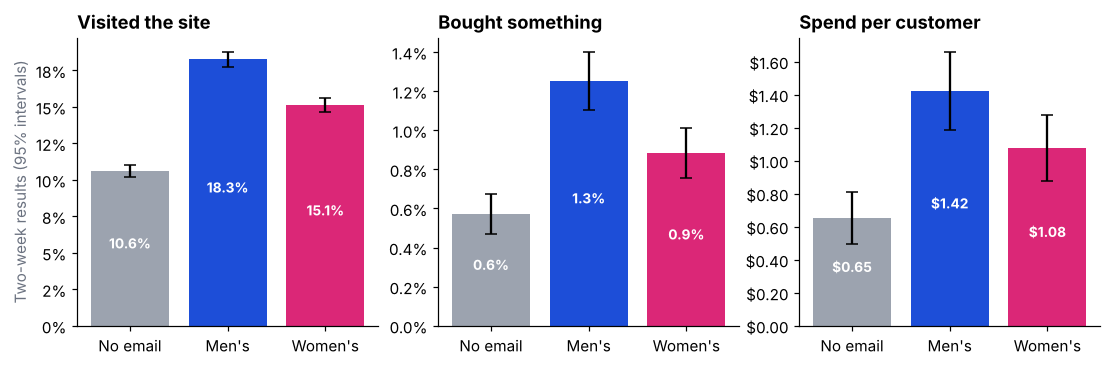

,arm,metric,control,treated,lift,low,high,relative,p_value
0,Men's email,visit,0.1062,0.1828,+0.0766,+0.0700,+0.0832,+72%,2.7e-113
1,Men's email,conversion,0.0057,0.0125,+0.0068,+0.0050,+0.0086,+119%,1.5e-13
2,Men's email,spend,0.6528,1.4226,+0.7698,+0.4851,+1.0545,+118%,1.2e-07
3,Women's email,visit,0.1062,0.1514,+0.0452,+0.0389,+0.0516,+43%,1.9e-44
4,Women's email,conversion,0.0057,0.0088,+0.0031,+0.0015,+0.0047,+54%,1.6e-04
5,Women's email,spend,0.6528,1.0772,+0.4244,+0.1690,+0.6799,+65%,1.1e-03


In [5]:
def lift_ci(y_t, y_c):
    diff = y_t.mean() - y_c.mean()
    se = np.sqrt(y_t.var(ddof=1) / len(y_t) + y_c.var(ddof=1) / len(y_c))
    return diff, diff - 1.96 * se, diff + 1.96 * se, 2 * stats.norm.sf(abs(diff / se))

ctrl = df[df["segment"] == "No E-Mail"]
rows = []
for arm in ARMS[1:]:
    t = df[df["segment"] == arm]
    for metric in ["visit", "conversion", "spend"]:
        d, lo, hi, p = lift_ci(t[metric], ctrl[metric])
        rows.append({"arm": LABEL[arm], "metric": metric, "control": ctrl[metric].mean(), "treated": t[metric].mean(),
                     "lift": d, "low": lo, "high": hi, "relative": t[metric].mean() / ctrl[metric].mean() - 1, "p_value": p})
lifts = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, metric, title, fmt in zip(axes, ["visit", "conversion", "spend"],
                                  ["Visited the site", "Bought something", "Spend per customer"],
                                  [mtick.PercentFormatter(1.0, decimals=0), mtick.PercentFormatter(1.0, decimals=1), mtick.StrMethodFormatter("${x:.2f}")]):
    vals = [df.loc[df["segment"] == a, metric] for a in ARMS]
    means = [v.mean() for v in vals]
    errs = [1.96 * v.std(ddof=1) / np.sqrt(len(v)) for v in vals]
    ax.bar(["No email", "Men's", "Women's"], means, yerr=errs, capsize=4, color=[COLORS[a] for a in ARMS])
    for i, m in enumerate(means):
        ax.text(i, m * 0.5, f"{m:.1%}" if metric != "spend" else f"${m:.2f}", ha="center", color="white", fontweight="bold", fontsize=9)
    ax.yaxis.set_major_formatter(fmt)
    ax.set_title(title)
axes[0].set_ylabel("Two-week results (95% intervals)", color=GREY)
fig.savefig(IMG / "01_readout.png")
plt.show()
lifts.style.format({"control": "{:.4f}", "treated": "{:.4f}", "lift": "{:+.4f}", "low": "{:+.4f}", "high": "{:+.4f}",
                    "relative": "{:+.0%}", "p_value": "{:.1e}"})

**Both emails clearly worked, and the men's email worked better on every measure:**

| | Men's email | Women's email |
|---|---|---|
| Site visits | **+7.7 pts** (10.6% → 18.3%, +72%) | +4.5 pts (+43%) |
| Purchases | **2.2×** the control rate | 1.5× |
| Extra spend per customer emailed | **+$0.77** (95% CI $0.49-$1.06) | +$0.42 ($0.17-$0.68) |

All six effects are statistically significant (p < 0.001). Note how much wider the spend intervals are than the visit intervals: that's the skewed spend at work.

## 3. Who responds to which email?

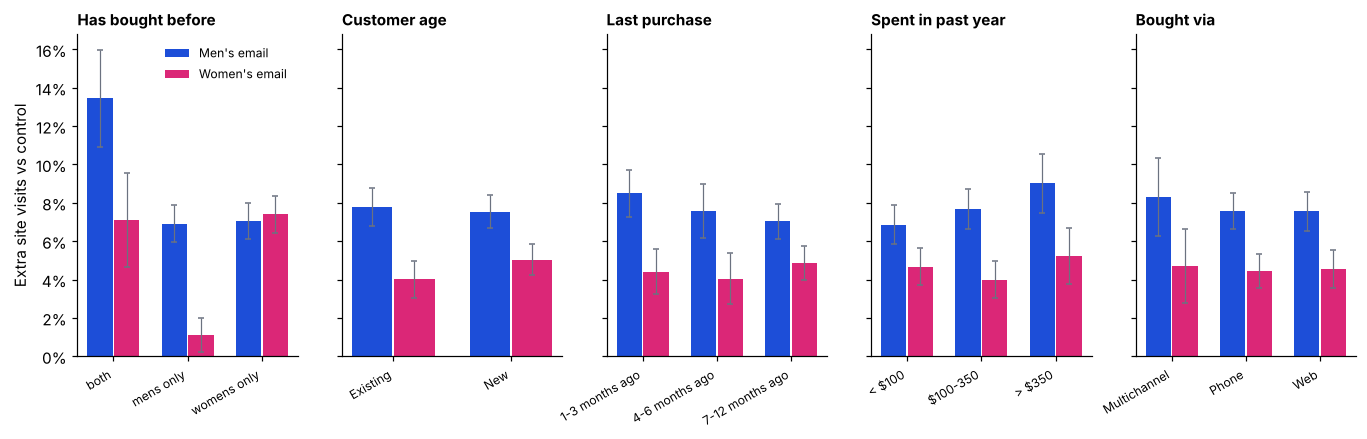

,buyer_type,arm,n,visit_pct,visit_lift_pts
0,both,Mens E-Mail,2181,31.5,13.4
1,both,Womens E-Mail,2118,25.2,7.1
2,mens only,Mens E-Mail,9558,16.9,6.9
3,mens only,Womens E-Mail,9622,11.1,1.1
4,womens only,Mens E-Mail,9568,16.6,7.1
5,womens only,Womens E-Mail,9647,17.0,7.4


In [6]:
def segment_lifts(col, metric="visit"):
    out = []
    for value, g in df.groupby(col, observed=True):
        c = g.loc[g["segment"] == "No E-Mail", metric]
        for arm in ARMS[1:]:
            d, lo, hi, _ = lift_ci(g.loc[g["segment"] == arm, metric], c)
            out.append({"segment": str(value), "arm": arm, "lift": d, "low": lo, "high": hi, "n": len(g)})
    return pd.DataFrame(out)

df["new_customer"] = df["newbie"].map({1: "New (last 12 months)", 0: "Existing"})
df["recency_band"] = pd.cut(df["recency"], [0, 3, 6, 12], labels=["1-3 months ago", "4-6 months ago", "7-12 months ago"])
df["spend_band"] = pd.cut(df["history"], [0, 100, 350, 1e9], labels=["< $100", "$100-350", "> $350"])
dims = [("buyer_type", "Has bought before"), ("new_customer", "Customer age"), ("recency_band", "Last purchase"),
        ("spend_band", "Spent in past year"), ("channel", "Bought via")]

fig, axes = plt.subplots(1, len(dims), figsize=(15, 3.8), sharey=True)
for ax, (col, title) in zip(axes, dims):
    s = segment_lifts(col)
    cats = list(dict.fromkeys(s["segment"]))
    for j, arm in enumerate(ARMS[1:]):
        sub = s[s["arm"] == arm].set_index("segment").loc[cats]
        x = np.arange(len(cats)) + (j - 0.5) * 0.36
        ax.bar(x, sub["lift"], width=0.34, color=COLORS[arm], label=LABEL[arm])
        ax.errorbar(x, sub["lift"], yerr=[sub["lift"] - sub["low"], sub["high"] - sub["lift"]], fmt="none", ecolor=GREY, capsize=2, lw=0.8)
    ax.set_xticks(range(len(cats)), [c.replace(" (last 12 months)", "") for c in cats], rotation=30, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.axhline(0, color=GREY, lw=0.6)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel("Extra site visits vs control")
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.savefig(IMG / "02_segments.png")
plt.show()
con.sql(queries[2]).df()

**The one big difference: the women's email barely works on men's-only buyers.** For customers who've only bought men's merchandise, the women's email adds just 1.1 points of visits, against 6.9 for the men's email. For women's-only buyers, the two emails work equally well (+7.4 vs +7.1).

The men's email is the safer choice: it works for every type of buyer. **Customers who've bought both lines respond the most** (+13 points to the men's email), which makes them the first group to target if the budget is limited.

Across the other dimensions (customer age, recency, past spend, channel), the effects are broadly similar. The intervals overlap, so I wouldn't build targeting on those differences.

## 4. Does personalisation pay?

The natural next step is a model that picks the best email for each customer: an **uplift model**. Here I use a *T-learner*: one gradient-boosting model per test group predicts each customer's outcome under each email, and the difference is the predicted uplift. Each customer then gets the email with the highest predicted uplift.

**How I test it fairly:** I train on 60% of customers and evaluate on the 40% holdout. Because the test was randomised, I can estimate how *any* targeting policy would have performed: I look at the holdout customers whose actual (random) email happens to match what the policy would have sent, and average their outcomes. This is called off-policy evaluation, and it means comparing policies on real outcomes rather than on model predictions.

In [7]:
features = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]],
                          columns=["zip_code", "channel"], dtype=float)
train_idx, test_idx = train_test_split(df.index, test_size=0.4, random_state=42, stratify=df["segment"])
test = df.loc[test_idx]

def t_learner(target):
    preds = {}
    for arm in ARMS:
        idx = [i for i in train_idx if df.at[i, "segment"] == arm]
        model = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200, random_state=0)
        model.fit(features.loc[idx], df.loc[idx, target])
        preds[arm] = model.predict(features.loc[test_idx])
    return pd.DataFrame(preds, index=test_idx)

def evaluate(policy):
    matched = test[test["segment"].values == policy.values]
    return matched[["visit", "conversion", "spend"]].mean()

pred_visit, pred_spend = t_learner("visit"), t_learner("spend")
cell_means = df.loc[train_idx].groupby(["buyer_type", "newbie", "segment"]).spend.mean().unstack()
cell_rule = test[["buyer_type", "newbie"]].apply(tuple, axis=1).map(cell_means.idxmax(axis=1).to_dict())

policies = {
    "No email": pd.Series("No E-Mail", index=test_idx),
    "Women's email to all": pd.Series("Womens E-Mail", index=test_idx),
    "Men's email to all": pd.Series("Mens E-Mail", index=test_idx),
    "Rule: women's email to women's-only buyers": pd.Series(np.where(test["buyer_type"] == "womens only", "Womens E-Mail", "Mens E-Mail"), index=test_idx),
    "Segment rule (best email per segment, by spend)": cell_rule,
    "Uplift model (visits)": pred_visit[ARMS[1:]].sub(pred_visit["No E-Mail"], axis=0).idxmax(axis=1),
    "Uplift model (spend)": pred_spend[ARMS[1:]].sub(pred_spend["No E-Mail"], axis=0).idxmax(axis=1),
}
results = pd.DataFrame({name: evaluate(p) for name, p in policies.items()}).T
results["matched customers"] = [int((test["segment"].values == p.values).sum()) for p in policies.values()]
results.style.format({"visit": "{:.2%}", "conversion": "{:.2%}", "spend": "${:.3f}", "matched customers": "{:,}"}) \
    .highlight_max(subset=["visit", "conversion", "spend"], props="font-weight:bold")

,visit,conversion,spend,matched customers
No email,10.22%,0.66%,$0.646,"8,522"
Women's email to all,15.48%,0.89%,$1.061,"8,555"
Men's email to all,17.86%,1.29%,$1.373,"8,523"
Rule: women's email to women's-only buyers,18.18%,1.22%,$1.322,"8,623"
"Segment rule (best email per segment, by spend)",16.57%,1.05%,$1.081,"8,600"
Uplift model (visits),18.27%,1.25%,$1.295,"8,647"
Uplift model (spend),17.70%,1.26%,$1.385,"8,475"


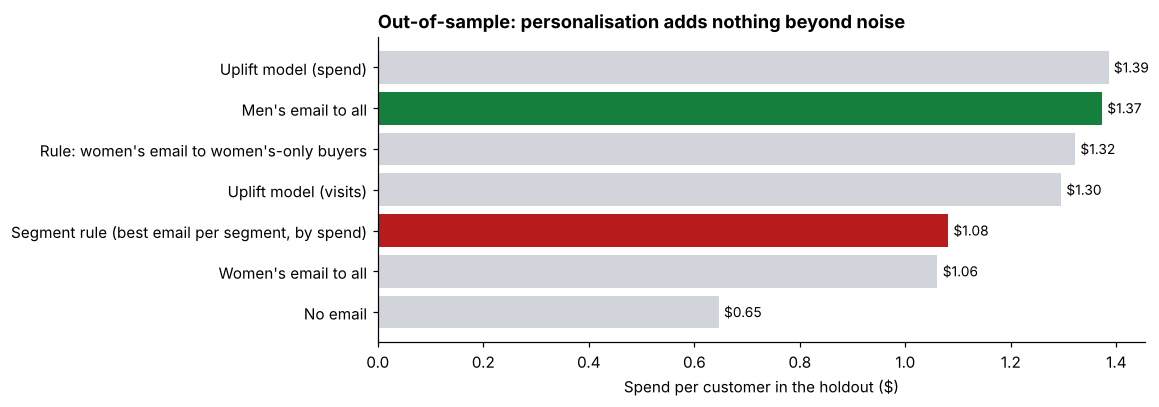

In [8]:
order = results.sort_values("spend").index
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [GREEN if n == "Men's email to all" else (RED if "Segment rule" in n else LIGHT) for n in order]
ax.barh(order, results.loc[order, "spend"], color=colors)
for y, v in enumerate(results.loc[order, "spend"]):
    ax.text(v + 0.01, y, f"${v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Spend per customer in the holdout ($)")
ax.set_title("Out-of-sample: personalisation adds nothing beyond noise")
fig.savefig(IMG / "03_policies.png")
plt.show()

**Personalisation doesn't beat "send everyone the men's email".**

- Each uplift model edges ahead on the metric it was trained for and falls behind on the other. The visit model gets the most visits but less spend, and the spend model gets slightly more spend ($1.39 vs $1.37) but fewer visits. All these differences are well within the holdout's noise: spend per customer has a 95% interval of roughly ±$0.30 at this sample size.
- The **segment rule**, which picks whichever email had the highest average spend in each segment of the training data, does clearly *worse* out of sample. With skewed spend, a handful of big orders made some segments look better than they were. This is overfitting, and it's exactly the trap a quick segment analysis in a BI tool can fall into.
- The rule "women's email for women's-only buyers" ties with the men's email to all. It's a reasonable creative choice, but not a revenue lever.

**Conclusion:** at this sample size, a simple rule is the right call. It performs as well as the models, and anyone in the team can understand and run it. Personalisation would need either bigger effects or many more customers to pay off. The uplift models are kept in the notebook so the comparison is reproducible.

## 5. Business case and budget planning

**Assumptions** (adjustable in the dashboard): 30% gross margin on incremental sales, and $0.10 total cost per email (production, sending, and an allowance for unsubscribes and fatigue).

In [9]:
MARGIN, COST = 0.30, 0.10
rng = np.random.default_rng(7)

def bootstrap_lift(arm, metric="spend", draws=2000):
    t = df.loc[df["segment"] == arm, metric].to_numpy()
    c = ctrl[metric].to_numpy()
    return np.array([rng.choice(t, len(t)).mean() - rng.choice(c, len(c)).mean() for _ in range(draws)])

boot = {arm: bootstrap_lift(arm) for arm in ARMS[1:]}
case = []
for arm, draws in boot.items():
    profit = draws * MARGIN - COST
    case.append({"email": LABEL[arm], "extra spend per email": draws.mean(), "profit per 1,000 emails": profit.mean() * 1000,
                 "90% range low": np.percentile(profit, 5) * 1000, "90% range high": np.percentile(profit, 95) * 1000,
                 "chance of a loss": (profit < 0).mean(), "break-even margin": COST / draws.mean()})
case = pd.DataFrame(case).set_index("email")
case.style.format({"extra spend per email": "${:.2f}", "profit per 1,000 emails": "${:,.0f}", "90% range low": "${:,.0f}",
                   "90% range high": "${:,.0f}", "chance of a loss": "{:.0%}", "break-even margin": "{:.0%}"})

,extra spend per email,"profit per 1,000 emails",90% range low,90% range high,chance of a loss,break-even margin
email,,,,,,
Men's email,$0.77,$130,$61,$199,0%,13%
Women's email,$0.43,$29,$-35,$92,24%,23%


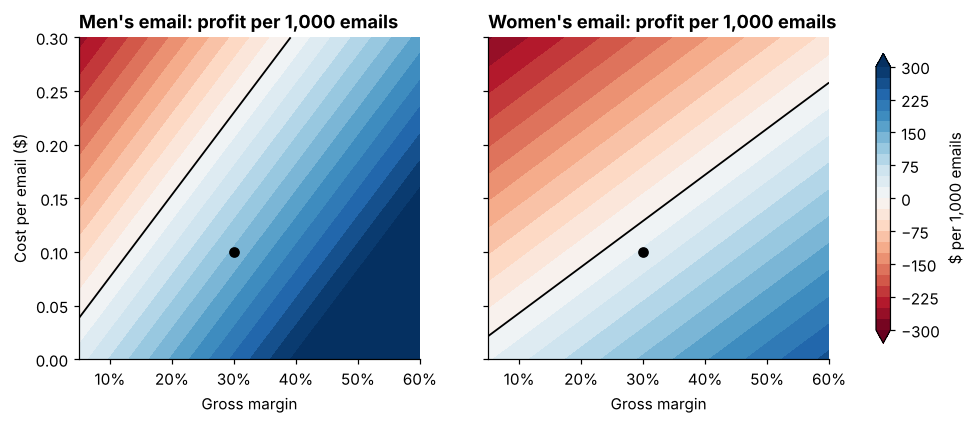

In [10]:
margins = np.linspace(0.05, 0.6, 56)
costs = np.linspace(0.0, 0.3, 61)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, arm in zip(axes, ARMS[1:]):
    m = boot[arm].mean()
    grid = np.array([[m * mg - c for mg in margins] for c in costs]) * 1000
    im = ax.contourf(margins, costs, grid, levels=np.linspace(-300, 300, 25), cmap="RdBu", extend="both")
    ax.contour(margins, costs, grid, levels=[0], colors="black", linewidths=1.2)
    ax.plot(MARGIN, COST, "o", color="black")
    ax.set_title(f"{LABEL[arm]}: profit per 1,000 emails")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("Gross margin")
axes[0].set_ylabel("Cost per email ($)")
fig.colorbar(im, ax=axes, label="$ per 1,000 emails", shrink=0.9)
fig.savefig(IMG / "04_break_even.png")
plt.show()

In [11]:
AUDIENCE = 500_000  # customers emailed per month in the planning scenario
plan = pd.DataFrame({
    LABEL[arm]: {
        "extra orders": AUDIENCE * lifts.loc[(lifts["arm"] == LABEL[arm]) & (lifts["metric"] == "conversion"), "lift"].iloc[0],
        "extra revenue": AUDIENCE * draws.mean(),
        "revenue, pessimistic (5th pct)": AUDIENCE * np.percentile(draws, 5),
        "revenue, optimistic (95th pct)": AUDIENCE * np.percentile(draws, 95),
        "campaign cost": AUDIENCE * COST,
        "expected profit": AUDIENCE * (draws.mean() * MARGIN - COST),
    } for arm, draws in boot.items()
}).T
plan.style.format("{:,.0f}")

,extra orders,extra revenue,"revenue, pessimistic (5th pct)","revenue, optimistic (95th pct)",campaign cost,expected profit
Men's email,"3,403","383,168","268,012","498,910","50,000","64,950"
Women's email,"1,556","214,891","108,570","320,139","50,000","14,467"


**At a 30% margin and $0.10 per email:**

- **The men's email earns about $130 profit per 1,000 emails**, with very little chance of a loss. It breaks even at a margin of about 13%.
- **The women's email is marginal**: about $29 per 1,000, a one-in-four chance of losing money, and break-even at a margin of about 23%.
- **For budget planning**, a monthly programme of 500,000 men's emails should bring in roughly 3,400 extra orders and $383k extra revenue. I'd plan on the pessimistic end of the interval (about $268k) rather than the average, because spend is skewed and the range is wide.

The break-even chart shows the decision boundary: every combination of margin and cost to the right of the black line makes money.

## 6. Recommendations

1. **Roll out the men's email to the whole base.** It works for every buyer type and is clearly profitable.
2. **Prioritise customers who've bought both lines** when budget or send volume is limited. They respond almost twice as strongly.
3. **Don't send the women's email to men's-only buyers.** It does almost nothing for them.
4. **Don't invest in personalisation yet.** Out of sample, uplift models did no better than a simple rule, and segment rules built on spend averages overfit. Revisit with more data or stronger creative differences.
5. **Always keep a random holdout group**, as this test did. Without the control group none of these numbers could be measured. Next tests worth running: subject lines, send frequency, and a "both lines" email for the most responsive segment.

**Limitations:** a two-week window from 2008 for one retailer, so the absolute numbers won't transfer to other businesses, but the method does. Margin and cost per email are assumptions. Long-term effects such as unsubscribes and fatigue aren't measured.